# ViSignLanguage - MediaPipe Tasks + BiLSTM Attention

## Cell 1 - Cài thư viện

In [ ]:
%pip -q install "mediapipe==0.10.32" "opencv-python-headless>=4.8" "scikit-learn>=1.4" "pandas>=2.0" "scipy" "huggingface_hub>=0.30" "joblib>=1.3" "tqdm>=4.66"

## Cell 2 - Drive, cấu hình, seed



In [ ]:
from google.colab import drive
from pathlib import Path
import os, json, random, zipfile, shutil, time, hashlib
import numpy as np
import pandas as pd
import tensorflow as tf
from tqdm.auto import tqdm
from collections import Counter

drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

ROOT = Path('/content/drive/MyDrive/ViSignLanguage_Project')
ROOT.mkdir(parents=True, exist_ok=True)
ZIP_PATH = ROOT / 'dataset.zip'                 # sua neu file zip nam o noi khac
DATA_DIR = Path('/content/visign_data')

# --- tham so du lieu / dac trung ---
T = 30; D = 204
LABELED_DIR = 'train'                           # chi video trong dataset/train/<nhan>/ co nhan
USE_TRACKING = False                            # False: moi frame doc lap (khuyen nghi cho clip ngan)
DROP_NO_HAND_TRAIN = True                       # bo mau TRAIN khong thay tay o frame nao (val/test giu nguyen)

# --- tham so huan luyen ---
EPOCHS = 100; BATCH_SIZE = 32
USE_AUG = True; AUG_PROB = 0.8                  # xac suat augment moi mau; phan con lai giu nguyen ban
LSTM_CUDNN = 'auto'                             # neu gap loi cuDNN tren Colab, doi thanh False

# --- thu muc (phien ban v3, tach rieng khoi cache cu) ---
TAG = 'trk' if USE_TRACKING else 'img'
CACHE = ROOT / f'features_v5_face_{TAG}'; CACHE.mkdir(exist_ok=True)
ART = ROOT / 'artifacts_v5_face'; ART.mkdir(exist_ok=True)
MODEL_DIR = ROOT / 'models_v5_face'; MODEL_DIR.mkdir(exist_ok=True)
RESULT_DIR = ROOT / 'results_v5_face'; RESULT_DIR.mkdir(exist_ok=True)
PRODUCT = ROOT / 'ViSignLanguage_Product_V5_Face'

print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
print('ZIP_PATH:', ZIP_PATH, '| ton tai:', ZIP_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
ZIP_PATH: /content/drive/MyDrive/ViSignLanguage_Project/dataset.zip | ton tai: True


## Cell 3 - Giải nén

In [ ]:
if not ZIP_PATH.exists():
    from huggingface_hub import hf_hub_download
    print('Khong tim thay zip tren Drive, tai tu Hugging Face...')
    ZIP_PATH = Path(hf_hub_download(repo_id='namwu/ViSignLanguage-Video', repo_type='dataset',
                                    filename='dataset.zip', local_dir='/content'))

marker = DATA_DIR / '.extracted_ok'
if not marker.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        for entry in z.infolist():
            target = (DATA_DIR / entry.filename).resolve()
            if not target.is_relative_to(DATA_DIR.resolve()):
                raise ValueError('Unsafe zip path: ' + entry.filename)
        z.extractall(DATA_DIR)
    marker.write_text('ok')
print('Extracted:', DATA_DIR)
print('Top level:', [p.name for p in DATA_DIR.iterdir() if p.name != '.extracted_ok'])

Extracted: /content/visign_data
Top level: ['dataset']


## Cell 4 - Khám phá cấu trúc, chỉ giữ video CÓ NHÃN



In [ ]:
import cv2, unicodedata

VIDEO_EXT = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}
DATASET_ROOT = DATA_DIR / 'dataset' if (DATA_DIR / 'dataset').is_dir() else DATA_DIR
all_videos = sorted(p for p in DATASET_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in VIDEO_EXT)
assert all_videos, 'Khong tim thay video. Kiem tra cau truc dataset sau giai nen.'

top = Counter(p.relative_to(DATASET_ROOT).parts[0] for p in all_videos)
print('Thu muc cap 1 va so video:', dict(top))

def is_labeled(p):
    parts = p.relative_to(DATASET_ROOT).parts
    return parts[0] == LABELED_DIR and len(parts) == 3

labeled = [p for p in all_videos if is_labeled(p)]
excluded = Counter(p.relative_to(DATASET_ROOT).parts[0] for p in all_videos if not is_labeled(p))
print(f'Giu {len(labeled)} video co nhan | bo qua {sum(excluded.values())} video khong nhan: {dict(excluded)}')

def group_of(path):
    return Path(path).stem.split('_')[0]

df = pd.DataFrame({'path': [str(p) for p in labeled],
                   'label': [unicodedata.normalize('NFC', p.parent.name) for p in labeled],
                   'group': [group_of(p) for p in labeled]})

# Chi giu video mo duoc va co frame
valid, rejected = [], []
for r in tqdm(df.itertuples(index=False), total=len(df), desc='Validate videos'):
    cap = cv2.VideoCapture(r.path)
    ok = cap.isOpened() and cap.get(cv2.CAP_PROP_FRAME_COUNT) > 0
    cap.release()
    (valid if ok else rejected).append(r._asdict())
df = pd.DataFrame(valid)
pd.DataFrame(rejected, columns=['path', 'label', 'group']).to_csv(ROOT / 'rejected_videos.csv', index=False)

n_groups = df.groupby('label')['group'].nunique()
print('Usable:', len(df), '| Rejected:', len(rejected))
print('So lop:', df.label.nunique(), '| so video goc (nhom):', df.groupby(['label', 'group']).ngroups)
print('Video/lop    :', df.label.value_counts().describe()[['min', '50%', 'max']].to_dict())
print('Nhom/lop     :', n_groups.describe()[['min', '50%', 'max']].to_dict())
assert df.label.nunique() >= 2
if df.label.nunique() != 100:
    print('CANH BAO: so lop khac 100, hay kiem tra lai LABELED_DIR / cau truc thu muc.')

Thu muc cap 1 va so video: {'private_test': 2859, 'public_test': 1630, 'train': 3875}
Giu 3875 video co nhan | bo qua 4489 video khong nhan: {'private_test': 2859, 'public_test': 1630}


Validate videos:   0%|          | 0/3875 [00:00<?, ?it/s]

Usable: 3875 | Rejected: 0
So lop: 100 | so video goc (nhom): 2806
Video/lop    : {'min': 6.0, '50%': 45.5, 'max': 74.0}
Nhom/lop     : {'min': 5.0, '50%': 32.5, 'max': 52.0}


In [ ]:

# CELL 4B - KIEM TRA VA LAM SACH DU LIEU

import hashlib
import pandas as pd

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

df = df.copy()
df["video_hash"] = df["path"].apply(sha256_file)

# 1. Phat hien trung lap byte
duplicate_rows = df[
    df.duplicated("video_hash", keep=False)
].copy()

# 2. Phat hien cung video nhung khac nhan
label_counts = df.groupby("video_hash")["label"].nunique()
conflict_hashes = set(
    label_counts[label_counts > 1].index
)

conflicts = df[
    df["video_hash"].isin(conflict_hashes)
].copy()

# 3. Luu bao cao
duplicate_rows.to_csv(
    ROOT / "duplicate_report.csv",
    index=False,
    encoding="utf-8-sig"
)

conflicts.to_csv(
    ROOT / "label_conflicts.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tong video ban dau:", len(df))
print("Nhom trung byte:",
      duplicate_rows["video_hash"].nunique())
print("Nhom trung khac nhan:", len(conflict_hashes))

# 4. Tam loai nhom co nhan mau thuan
df_clean = df[
    ~df["video_hash"].isin(conflict_hashes)
].copy()

# 5. Moi video trung byte chi giu 1 ban
df_clean = df_clean.drop_duplicates(
    subset="video_hash",
    keep="first"
).reset_index(drop=True)

# 6. Kiem tra ket qua
print("Video sau lam sach:", len(df_clean))
print("So lop con lai:", df_clean["label"].nunique())
print("Ban ghi da loai:", len(df) - len(df_clean))

assert df_clean["video_hash"].is_unique
assert df_clean["label"].nunique() == 100, (
    "Co lop bi mat sau khi loc. "
    "Can kiem tra label_conflicts.csv"
)

# 7. Chuyen sang du lieu sach
df = df_clean.copy()

print("CELL 4B - DATA CLEANING OK")


Tong video ban dau: 3875
Nhom trung byte: 550
Nhom trung khac nhan: 2
Video sau lam sach: 2774
So lop con lai: 100
Ban ghi da loai: 1101
CELL 4B - DATA CLEANING OK


## Cell 5 - Chia 70/15/15 theo NHÓM trước khi trích xuất và fit scaler



In [ ]:

# CELL 5 - CHIA DU LIEU SAU KHI LAM SACH

import numpy as np
import pandas as pd

assert "video_hash" in df.columns, (
    "Phai chay Cell 4B truoc Cell 5"
)

rng = np.random.default_rng(SEED)

parts = {
    "train": [],
    "val": [],
    "test": []
}

# Cap nhat so nhom sau khi lam sach
n_groups = df.groupby("label")["group"].nunique()

# Chia theo nhom video goc cua tung lop
for label, g in df.groupby("label"):

    groups = np.array(sorted(g["group"].unique()))
    rng.shuffle(groups)

    n = len(groups)

    if n < 3:
        raise ValueError(
            f"Lop {label} chi con {n} nhom, "
            "khong du chia 3 tap."
        )

    n_val = max(1, round(n * 0.15))
    n_test = max(1, round(n * 0.15))
    n_train = n - n_val - n_test

    if n_train < 1:
        raise ValueError(
            f"Lop {label} khong con nhom train"
        )

    selected = {
        "train": groups[:n_train],
        "val": groups[n_train:n_train+n_val],
        "test": groups[n_train+n_val:]
    }

    for split, group_ids in selected.items():
        part = g[g["group"].isin(group_ids)]
        parts[split].append(part)

train_df = pd.concat(
    parts["train"], ignore_index=True
)
val_df = pd.concat(
    parts["val"], ignore_index=True
)
test_df = pd.concat(
    parts["test"], ignore_index=True
)

# KIEM TRA RO RI DU LIEU
splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df
}

for name_a, name_b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    a = splits[name_a]
    b = splits[name_b]

    # Khong trung noi dung video
    assert set(a["video_hash"]).isdisjoint(
        set(b["video_hash"])
    ), f"TRUNG BYTE: {name_a} - {name_b}"

    # Khong trung nhom goc trong cung lop
    keys_a = set(zip(a["label"], a["group"]))
    keys_b = set(zip(b["label"], b["group"]))

    assert keys_a.isdisjoint(keys_b), (
        f"TRUNG NHOM: {name_a} - {name_b}"
    )

# KIEM TRA DU 100 LOP
for name, part in splits.items():

    assert part["label"].nunique() == 100, (
        f"Tap {name} khong du 100 lop"
    )

    print(
        name.upper(),
        "| Video:", len(part),
        "| Lop:", part["label"].nunique(),
        "| Ty le:", f"{len(part)/len(df):.2%}"
    )

    part.to_csv(
        ROOT / f"{name}_manifest.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("\nCELL 5 - SPLIT OK")
print("Khong trung byte giua Train/Val/Test")
print("Khong trung nhom ten file trong cung lop")


TRAIN | Video: 1938 | Lop: 100 | Ty le: 69.86%
VAL | Video: 418 | Lop: 100 | Ty le: 15.07%
TEST | Video: 418 | Lop: 100 | Ty le: 15.07%

CELL 5 - SPLIT OK
Khong trung byte giua Train/Val/Test
Khong trung nhom ten file trong cung lop


## Cell 6A - Module đặc trưng `visign_features.py`




In [ ]:
%%writefile visign_features.py
"""
visign_features.py - Video -> X (30, 204). Dùng CHUNG cho huấn luyện và suy luận để hai bên luôn khớp nhau.

Bố cục 204 đặc trưng mỗi frame (mỗi điểm gồm x, y, z):
    [  0: 63]  tay "Left"  (21 điểm)   theo nhãn handedness của MediaPipe
    [ 63:126]  tay "Right" (21 điểm)
    [126:144]  pose 6 điểm: vai, khuỷu, cổ tay
    [144:204]  face 20 điểm: mắt, lông mày, miệng
Điểm không phát hiện được = 0 (cả khối). Nhãn Left/Right của MediaPipe giả định ảnh gương (selfie); ta chỉ cần
dùng NHẤT QUÁN giữa huấn luyện và suy luận, không cần nó khớp với tay thật.

Chuẩn hoá: tâm = trung điểm hai vai, tỉ lệ = bề rộng vai (trung vị theo video).
"""
import os
import urllib.request
from pathlib import Path

import cv2
import numpy as np

T = 30
D = 204
POSE_IDS = [11, 12, 13, 14, 15, 16]
FACE_IDS = [33,133,362,263,159,145,386,374,70,63,105,107,336,334,293,300,61,291,13,14]
LH, RH, PS, FC = slice(0, 63), slice(63, 126), slice(126, 144), slice(144, 204)
BLOCKS = (LH, RH, PS, FC)
SIDE = {"Left": 0, "Right": 1}

MODEL_DIR = Path(os.environ.get("VISIGN_MODEL_DIR", "/content/mp_models"))
HAND_MODEL = MODEL_DIR / "hand_landmarker.task"
POSE_MODEL = MODEL_DIR / "pose_landmarker_lite.task"
FACE_MODEL = MODEL_DIR / "face_landmarker.task"
HAND_URL = ("https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/"
            "hand_landmarker.task")
POSE_URL = ("https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/"
            "pose_landmarker_lite.task")
FACE_URL = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task")
_TS = [0]   # timestamp cho chế độ tracking (VIDEO)


def ensure_models():
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    for path, url in ((HAND_MODEL, HAND_URL), (POSE_MODEL, POSE_URL), (FACE_MODEL, FACE_URL)):
        if not path.exists() or path.stat().st_size == 0:
            print("Downloading:", path.name)
            urllib.request.urlretrieve(url, path)


def make_detectors(use_tracking=False):
    """use_tracking=False: chế độ IMAGE, mỗi frame độc lập, không có trạng thái giữa các video (khuyến nghị cho
    clip ngắn). use_tracking=True: chế độ VIDEO (có tracking), cần timestamp tăng dần."""
    import mediapipe as mp  # noqa: F401
    from mediapipe.tasks import python
    from mediapipe.tasks.python import vision
    ensure_models()
    mode = vision.RunningMode.VIDEO if use_tracking else vision.RunningMode.IMAGE
    hand = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=str(HAND_MODEL)), running_mode=mode, num_hands=2,
        min_hand_detection_confidence=0.5, min_hand_presence_confidence=0.5, min_tracking_confidence=0.5))
    pose = vision.PoseLandmarker.create_from_options(vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=str(POSE_MODEL)), running_mode=mode, num_poses=1,
        min_pose_detection_confidence=0.5, min_pose_presence_confidence=0.5, min_tracking_confidence=0.5))
    face = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=str(FACE_MODEL)), running_mode=mode,
        num_faces=1, min_face_detection_confidence=0.5,
        min_face_presence_confidence=0.5, min_tracking_confidence=0.5,
        output_face_blendshapes=False, output_facial_transformation_matrixes=False))
    return hand, pose, face


# ----------------------------------------------------------------------------
# Landmark -> vector 144 chiều (chưa chuẩn hoá)
# ----------------------------------------------------------------------------
def to_feature(hand_result, pose_result, face_result):
    f = np.zeros(D, np.float32)
    best = {}                                   # side -> (score, landmarks); mỗi bên giữ bàn tay điểm cao nhất
    hands, handed = hand_result.hand_landmarks, getattr(hand_result, "handedness", None) or []
    for k, lms in enumerate(hands[:2]):
        if len(lms) != 21 or k >= len(handed) or not handed[k]:
            continue
        cat = handed[k][0]
        side = SIDE.get(cat.category_name)
        if side is not None and (side not in best or cat.score > best[side][0]):
            best[side] = (cat.score, lms)
    for side, (_, lms) in best.items():
        f[side * 63:(side + 1) * 63] = np.array([[p.x, p.y, p.z] for p in lms], np.float32).reshape(-1)
    if pose_result.pose_landmarks:
        lms = pose_result.pose_landmarks[0]
        if len(lms) > max(POSE_IDS):
            f[PS] = np.array([[lms[i].x, lms[i].y, lms[i].z] for i in POSE_IDS], np.float32).reshape(-1)
    if face_result.face_landmarks:
        lms = face_result.face_landmarks[0]
        if len(lms) > max(FACE_IDS):
            f[FC] = np.array([[lms[i].x, lms[i].y, lms[i].z] for i in FACE_IDS], np.float32).reshape(-1)
    return f


# ----------------------------------------------------------------------------
# Chuẩn hoá theo cơ thể
# ----------------------------------------------------------------------------
def body_reference(arr):
    """(tâm (3,), tỉ lệ) từ hai vai (trung vị theo video); None nếu không có frame nào thấy pose."""
    ok = np.any(arr[:, PS] != 0, axis=1)
    if not ok.any():
        return None
    pose = arr[ok, PS].reshape(-1, 6, 3)
    ls, rs = pose[:, 0], pose[:, 1]
    scale = float(np.median(np.linalg.norm((ls - rs)[:, :2], axis=1)))
    if scale < 0.02:
        return None
    return np.median((ls + rs) / 2, axis=0).astype(np.float32), scale


def normalize_sequence(arr):
    """(T,204) toạ độ ảnh -> toạ độ theo thân người. Điểm thiếu giữ nguyên 0.
    Pose: (v - tâm) / tỉ lệ. Tay: x,y theo (v - tâm) / tỉ lệ; z chỉ chia tỉ lệ (z của tay tính so với cổ tay).
    Trả về (mảng đã chuẩn hoá, đã_dùng_vai: bool). Không thấy vai -> dùng tâm (0.5, 0.5), tỉ lệ 0.25."""
    ref = body_reference(arr)
    found = ref is not None
    center, scale = ref if found else (np.array([0.5, 0.5, 0.0], np.float32), 0.25)
    out = np.zeros_like(arr, dtype=np.float32)
    n = len(arr)
    for sl in (LH, RH):
        present = np.any(arr[:, sl] != 0, axis=1)
        h = arr[:, sl].reshape(n, 21, 3).copy()
        h[..., :2] = (h[..., :2] - center[:2]) / scale
        h[..., 2] = h[..., 2] / scale
        h[~present] = 0
        out[:, sl] = h.reshape(n, 63)
    present = np.any(arr[:, PS] != 0, axis=1)
    p = (arr[:, PS].reshape(n, 6, 3) - center) / scale
    p[~present] = 0
    out[:, PS] = p.reshape(n, 18)
    face_present = np.any(arr[:, FC] != 0, axis=1)
    face_pts = arr[:, FC].reshape(n, len(FACE_IDS), 3).copy()
    face_pts[..., :2] = (face_pts[..., :2] - center[:2]) / scale
    face_pts[..., 2] = face_pts[..., 2] / scale
    face_pts[~face_present] = 0
    out[:, FC] = face_pts.reshape(n, 60)
    return np.clip(out, -8.0, 8.0), found


# ----------------------------------------------------------------------------
# Video -> (30, 144)
# ----------------------------------------------------------------------------
def read_selected(path, n_samples=T):
    """Đọc đúng n_samples frame trải đều trên video (đếm frame thật, không tin CAP_PROP_FRAME_COUNT).
    Trả về (dict chỉ_số -> frame BGR, danh sách chỉ_số_cần_lấy có thể lặp khi video ngắn)."""
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {path}")
    n = 0
    while cap.grab():
        n += 1
    cap.release()
    if n <= 0:
        raise ValueError(f"Empty video: {path}")
    wanted = np.linspace(0, n - 1, n_samples).round().astype(int)
    need = set(wanted.tolist())
    cap = cv2.VideoCapture(str(path))
    frames, idx = {}, 0
    while idx < n and len(frames) < len(need):
        if not cap.grab():
            break
        if idx in need:
            ok, f = cap.retrieve()
            if ok:
                frames[idx] = f
        idx += 1
    cap.release()
    if not frames:
        raise ValueError(f"No decodable frames: {path}")
    last = None
    fixed = []
    for w in wanted:                         # frame không đọc được -> dùng frame hợp lệ gần nhất trước đó
        if int(w) in frames:
            last = int(w)
        elif last is None:
            last = min(frames)
        fixed.append(last)
    return frames, fixed


def process_video(path, hand, pose, face, T_=T, use_tracking=False, return_ref_flag=False):
    import mediapipe as mp
    frames, wanted = read_selected(path, T_)
    feats = {}
    for idx in sorted(set(wanted)):
        rgb = cv2.cvtColor(frames[idx], cv2.COLOR_BGR2RGB)
        img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
        if use_tracking:
            _TS[0] += 33
            hr, pr, fr = hand.detect_for_video(img, _TS[0]), pose.detect_for_video(img, _TS[0]), face.detect_for_video(img, _TS[0])
        else:
            hr, pr, fr = hand.detect(img), pose.detect(img), face.detect(img)
        feats[idx] = to_feature(hr, pr, fr)
    arr = np.stack([feats[i] for i in wanted])
    arr, found = normalize_sequence(arr)
    if arr.shape != (T_, D) or not np.isfinite(arr).all():
        raise ValueError(f"Invalid features {arr.shape} for {path}")
    return (arr, found) if return_ref_flag else arr


def sequence_stats(arr):
    """Tỉ lệ frame phát hiện được tay trái/phải/pose của một chuỗi (T,144) đã chuẩn hoá."""
    pres = [np.any(arr[:, sl] != 0, axis=1).mean() for sl in BLOCKS]
    return dict(left_rate=float(pres[0]), right_rate=float(pres[1]), pose_rate=float(pres[2]), face_rate=float(pres[3]),
                any_hand_rate=float(np.any([np.any(arr[:, s] != 0, axis=1) for s in (LH, RH)], axis=0).mean()))


# ----------------------------------------------------------------------------
# Scaler chỉ dùng giá trị CÓ THẬT (điểm thiếu = 0 không làm lệch mean/std)
# ----------------------------------------------------------------------------
def present_mask(X):
    """Mặt nạ bool cùng shape X: True nếu cả khối (tay trái / tay phải / pose) có dữ liệu ở frame đó."""
    M = np.zeros(np.shape(X), bool)
    for sl in BLOCKS:
        M[..., sl] = np.any(np.asarray(X)[..., sl] != 0, axis=-1, keepdims=True)
    return M


def fit_masked_scaler(X_train):
    """Trả về sklearn StandardScaler (lưu được bằng joblib như bình thường) với mean/std tính trên giá trị có thật."""
    from sklearn.preprocessing import StandardScaler
    Xf = np.asarray(X_train, np.float64).reshape(-1, D)
    M = present_mask(X_train).reshape(-1, D)
    cnt = M.sum(0)
    mean = np.where(cnt > 0, (Xf * M).sum(0) / np.maximum(cnt, 1), 0.0)
    var = np.where(cnt > 0, (((Xf - mean) ** 2) * M).sum(0) / np.maximum(cnt, 1), 1.0)
    std = np.sqrt(var)
    std[std < 1e-6] = 1.0
    sc = StandardScaler()
    sc.mean_, sc.scale_, sc.var_ = mean, std, std ** 2
    sc.n_features_in_, sc.n_samples_seen_ = D, int(cnt.max())
    return sc


def apply_scaler(X, scaler):
    """Chuẩn hoá (..., T, 204); điểm thiếu giữ nguyên 0 sau chuẩn hoá."""
    X = np.asarray(X, np.float32)
    M = present_mask(X)
    out = ((X - scaler.mean_) / scaler.scale_).astype(np.float32)
    out[~M] = 0.0
    return out


def scale_array(X, scaler=None):
    """Tương thích với tên hàm cũ trong notebook. Cần truyền scaler (hoặc gán scale_array.scaler)."""
    sc = scaler if scaler is not None else getattr(scale_array, "scaler", None)
    if sc is None:
        raise RuntimeError("Chưa có scaler: gọi scale_array(X, scaler) hoặc đặt scale_array.scaler = scaler")
    return apply_scaler(X, sc)


Overwriting visign_features.py


## Cell 6B - Nạp module, tải model MediaPipe và kiểm thử trên 5 video



In [ ]:
import sys
sys.path.insert(0, '/content')
import importlib, visign_features as V
importlib.reload(V)
assert V.T == T and V.D == D

hand_detector, pose_detector, face_detector = V.make_detectors(USE_TRACKING)
print('Hand model:', V.HAND_MODEL.exists(), '| Pose model:', V.POSE_MODEL.exists(), '| Face model:', V.FACE_MODEL.exists())
with hand_detector as hand, pose_detector as pose, face_detector as face:
    for i, row in enumerate(train_df.head(5).itertuples(index=False)):
        arr, found = V.process_video(row.path, hand, pose, face, T, USE_TRACKING, return_ref_flag=True)
        st = V.sequence_stats(arr)
        msg = f'Video {i+1}: {arr.shape} | finite={np.isfinite(arr).all()} | Left {st["left_rate"]:.2f} Right {st["right_rate"]:.2f} Pose {st["pose_rate"]:.2f} Face {st["face_rate"]:.2f}'
        if found:
            sh = arr[:, V.PS].reshape(T, 6, 3)
            ok = np.any(arr[:, V.PS] != 0, axis=1)
            width = np.linalg.norm(sh[ok, 0, :2] - sh[ok, 1, :2], axis=1).mean()
            mid = ((sh[ok, 0, :2] + sh[ok, 1, :2]) / 2).mean()
            msg += f' | be rong vai={width:.2f} (ky vong ~1), tam={mid:.2f} (ky vong ~0)'
        else:
            msg += ' | KHONG THAY VAI -> dung tham chieu mac dinh'
        print(msg)

Downloading: face_landmarker.task
Hand model: True | Pose model: True | Face model: True
Video 1: (30, 204) | finite=True | Left 0.83 Right 0.37 Pose 1.00 Face 1.00 | be rong vai=0.98 (ky vong ~1), tam=-0.00 (ky vong ~0)
Video 2: (30, 204) | finite=True | Left 0.00 Right 0.00 Pose 0.33 Face 0.33 | be rong vai=1.00 (ky vong ~1), tam=0.00 (ky vong ~0)
Video 3: (30, 204) | finite=True | Left 0.67 Right 0.53 Pose 1.00 Face 1.00 | be rong vai=1.00 (ky vong ~1), tam=-0.00 (ky vong ~0)
Video 4: (30, 204) | finite=True | Left 0.83 Right 0.73 Pose 1.00 Face 1.00 | be rong vai=1.00 (ky vong ~1), tam=0.00 (ky vong ~0)
Video 5: (30, 204) | finite=True | Left 0.87 Right 0.60 Pose 1.00 Face 1.00 | be rong vai=1.00 (ky vong ~1), tam=0.00 (ky vong ~0)


## Cell 7 - Trích xuất toàn bộ video CÓ NHÃN, cache `.npy`, nhật ký lỗi và QC



In [ ]:
def extract_manifest(part, name):
    folder = CACHE / name; folder.mkdir(parents=True, exist_ok=True)
    good, bad = [], []
    hand_detector, pose_detector, face_detector = V.make_detectors(USE_TRACKING)
    with hand_detector as hand, pose_detector as pose, face_detector as face:
        for row in tqdm(part.itertuples(index=False), total=len(part), desc=name):
            key = hashlib.sha256(row.path.encode('utf-8')).hexdigest()[:24]
            out = folder / (key + '.npy')
            try:
                if out.exists():
                    arr = np.load(out)
                    if arr.shape != (T, D):
                        raise ValueError('Bad cached shape')
                else:
                    arr = V.process_video(row.path, hand, pose, face, T, USE_TRACKING)
                    np.save(out, arr)
                good.append({'feature': str(out), 'path': row.path, 'label': row.label, 'group': row.group,
                             **V.sequence_stats(arr)})
            except Exception as e:
                bad.append({'path': row.path, 'label': row.label, 'error': str(e)})
    pd.DataFrame(good).to_csv(ROOT / f'{name}_features.csv', index=False)
    pd.DataFrame(bad, columns=['path', 'label', 'error']).to_csv(ROOT / f'{name}_errors.csv', index=False)
    print(name, 'OK', len(good), '| loi', len(bad))
    return pd.DataFrame(good)

train_feat = extract_manifest(train_df, 'train')
val_feat = extract_manifest(val_df, 'val')
test_feat = extract_manifest(test_df, 'test')
assert min(len(train_feat), len(val_feat), len(test_feat)) > 0

qc = pd.concat([train_feat.assign(split='train'), val_feat.assign(split='val'), test_feat.assign(split='test')])
print('\nQC trich xuat (trung binh ti le frame phat hien duoc):')
print(qc.groupby('split')[['left_rate', 'right_rate', 'pose_rate', 'face_rate', 'any_hand_rate']].mean().round(3))
print('Mau khong thay tay o frame nao :', int((qc.any_hand_rate == 0).sum()), '/', len(qc))
print('Mau khong thay pose o frame nao:', int((qc.pose_rate == 0).sum()), '/', len(qc))
qc.to_csv(RESULT_DIR / 'extraction_qc.csv', index=False)

train:   0%|          | 0/1938 [00:00<?, ?it/s]

train OK 1938 | loi 0


val:   0%|          | 0/418 [00:00<?, ?it/s]

val OK 418 | loi 0


test:   0%|          | 0/418 [00:00<?, ?it/s]

test OK 418 | loi 0

QC trich xuat (trung binh ti le frame phat hien duoc):
       left_rate  right_rate  pose_rate  face_rate  any_hand_rate
split                                                            
test       0.579       0.687      0.925      0.916          0.774
train      0.571       0.671      0.915      0.905          0.766
val        0.541       0.646      0.920      0.912          0.740
Mau khong thay tay o frame nao : 42 / 2774
Mau khong thay pose o frame nao: 2 / 2774


In [ ]:

# ==========================================================
# CELL 7B - FEATURE QUALITY CONTROL + DUPLICATE CHECK
# ==========================================================

import numpy as np
import pandas as pd
import hashlib
from pathlib import Path

splits = ["train", "val", "test"]
all_parts = []
qc_rows = []

# 1. DOC MANIFEST FEATURE
for split in splits:
    manifest = ROOT / f"{split}_features.csv"

    if not manifest.exists():
        raise FileNotFoundError(
            f"Khong tim thay manifest: {manifest}"
        )

    part = pd.read_csv(manifest)
    part["split"] = split

    required = {"path", "label", "feature"}
    missing = required - set(part.columns)

    if missing:
        raise ValueError(
            f"{manifest.name} thieu cot: {missing}"
        )

    all_parts.append(part)

all_features = pd.concat(
    all_parts, ignore_index=True
)

# 2. KIEM TRA SHAPE, NaN, Inf, MASK, LANDMARKS
def inspect_feature(path):
    x = np.load(path, allow_pickle=False)

    valid_shape = x.shape == (30, 204)
    finite = bool(np.isfinite(x).all())

    if not valid_shape or not finite:
        return {
            "valid_shape": valid_shape,
            "finite": finite,
            "missing_ratio": np.nan,
            "nonzero_ratio": np.nan,
            "feature_hash": None
        }

    # Ty le gia tri bang 0 (proxy, khong phai mask goc)
    missing_ratio = float(np.mean(x == 0))
    nonzero_ratio = float(np.mean(x != 0))

    h = hashlib.sha256()
    h.update(str(x.shape).encode())
    h.update(str(x.dtype).encode())
    h.update(np.ascontiguousarray(x).tobytes())

    return {
        "valid_shape": True,
        "finite": True,
        "missing_ratio": missing_ratio,
        "nonzero_ratio": nonzero_ratio,
        "feature_hash": h.hexdigest()
    }

for _, row in all_features.iterrows():
    info = inspect_feature(row["feature"])

    qc_rows.append({
        "split": row["split"],
        "label": row["label"],
        "path": row["path"],
        "feature": row["feature"],
        **info
    })

qc_df = pd.DataFrame(qc_rows)

# 3. THONG KE CHAT LUONG FEATURE
print("========== FEATURE QUALITY ==========")
print("Tong video:", len(qc_df))
print("Shape hop le:", int(qc_df["valid_shape"].sum()))
print("Finite:", int(qc_df["finite"].sum()))

valid_qc = qc_df[
    qc_df["valid_shape"] & qc_df["finite"]
]

print(
    "Ty le gia tri bang 0 trung binh:",
    round(valid_qc["missing_ratio"].mean(), 4)
)

print(
    "Ty le gia tri khac 0 trung binh:",
    round(valid_qc["nonzero_ratio"].mean(), 4)
)

# 4. KIEM TRA TRUNG FEATURE
groups = (
    valid_qc.groupby("feature_hash")
    .agg(
        so_video=("path", "size"),
        so_split=("split", "nunique"),
        so_nhan=("label", "nunique")
    )
    .reset_index()
)

duplicates = groups[groups["so_video"] > 1]
cross_split = groups[groups["so_split"] > 1]
conflicts = groups[groups["so_nhan"] > 1]

print("\n========== DUPLICATE CHECK ==========")
print("Nhom feature trung:", len(duplicates))
print("Nhom trung giua cac tap:", len(cross_split))
print("Nhom feature khac nhan:", len(conflicts))

# 5. LUU BAO CAO
RESULT_DIR.mkdir(parents=True, exist_ok=True)

qc_df.to_csv(
    RESULT_DIR / "feature_quality_report.csv",
    index=False,
    encoding="utf-8-sig"
)

duplicate_hashes = set(
    duplicates["feature_hash"]
)

duplicate_details = valid_qc[
    valid_qc["feature_hash"].isin(duplicate_hashes)
]

duplicate_details.to_csv(
    RESULT_DIR / "feature_duplicates.csv",
    index=False,
    encoding="utf-8-sig"
)

# 6. KIEM TRA TRUOC KHI TRAIN
if not qc_df["valid_shape"].all():
    raise RuntimeError(
        "Co feature sai shape (30, 204)."
    )

if not qc_df["finite"].all():
    raise RuntimeError(
        "Co feature chua NaN hoac Inf."
    )

if len(cross_split) > 0:
    raise RuntimeError(
        "PHAT HIEN FEATURE TRUNG GIUA TRAIN/VAL/TEST. "
        "Hay kiem tra feature_duplicates.csv."
    )

if len(conflicts) > 0:
    print(
        "CANH BAO: Co feature trung nhung khac nhan."
    )

print("\nCELL 7B - QUALITY CONTROL COMPLETED")
print("Bao cao:", RESULT_DIR)


========== FEATURE QUALITY ==========
Tong video: 2774
Shape hop le: 2774
Finite: 2774
Ty le gia tri bang 0 trung binh: 0.2701
Ty le gia tri khac 0 trung binh: 0.7299

========== DUPLICATE CHECK ==========
Nhom feature trung: 2
Nhom trung giua cac tap: 0
Nhom feature khac nhan: 1
CANH BAO: Co feature trung nhung khac nhan.

CELL 7B - QUALITY CONTROL COMPLETED
Bao cao: /content/drive/MyDrive/ViSignLanguage_Project/results_v5_face


## Cell 8 - Nạp đặc trưng, fit scaler CHỈ trên train, lưu encoder/scaler/config



In [ ]:
import joblib
from sklearn.preprocessing import LabelEncoder

train_f = pd.read_csv(ROOT / 'train_features.csv')
val_f = pd.read_csv(ROOT / 'val_features.csv')
test_f = pd.read_csv(ROOT / 'test_features.csv')

# Loai mau train khong co thong tin ban tay (bao ve: moi lop con it nhat 3 mau)
dropped = 0
if DROP_NO_HAND_TRAIN:
    bad = (train_f.any_hand_rate == 0).to_numpy()
    keep = ~bad
    for lab, idx in train_f.groupby('label').indices.items():
        if keep[idx].sum() < 3:
            keep[idx] = True
    dropped = int((~keep).sum())
    train_f = train_f[keep].reset_index(drop=True)
print('Mau train bi loai (khong thay tay):', dropped)

def load_features(d):
    arrays = []
    for path in d['feature']:
        x = np.load(path).astype(np.float32)
        if x.shape != (T, D) or not np.isfinite(x).all():
            raise ValueError(f'Feature loi: {path}: {x.shape}')
        arrays.append(x)
    return np.stack(arrays)

Xtr_raw, Xva_raw, Xte_raw = load_features(train_f), load_features(val_f), load_features(test_f)

# Ma hoa nhan (chi fit tren train) va kiem tra val/test khong co lop la
le = LabelEncoder()
y_train = le.fit_transform(train_f['label'])
assert set(val_f.label) <= set(le.classes_) and set(test_f.label) <= set(le.classes_), 'Val/test co lop khong co o train'
y_val, y_test = le.transform(val_f['label']), le.transform(test_f['label'])
NUM_CLASSES = len(le.classes_)

# Scaler chi tren gia tri co that, chi fit tren train
scaler = V.fit_masked_scaler(Xtr_raw)
X_val = V.apply_scaler(Xva_raw, scaler)
X_test = V.apply_scaler(Xte_raw, scaler)
V.scale_array.scaler = scaler

# Trong so lop (can bang nhe): can bac hai cua nghich dao tan suat
counts = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float64)
class_weight = (counts.mean() / counts) ** 0.5
sample_weight_train = class_weight[y_train].astype(np.float32)

# Kiem tra: thieu van bang 0, gia tri co that co trung binh ~0, do lech ~1
Mva = V.present_mask(Xva_raw)
print('Diem thieu giu 0 sau scale:', bool((X_val[~Mva] == 0).all()))
print('Gia tri co that sau scale: mean=%.3f std=%.3f' % (X_val[Mva].mean(), X_val[Mva].std()))

joblib.dump(scaler, ART / 'scaler.pkl')
joblib.dump(le, ART / 'label_encoder.pkl')
config = {
    'version': 'v5_face',
    'num_classes': NUM_CLASSES, 'timesteps': T, 'features': D,
    'train_samples': len(Xtr_raw), 'val_samples': len(Xva_raw), 'test_samples': len(Xte_raw),
    'feature_layout': {'0:63': 'tay Left (21 diem x,y,z)', '63:126': 'tay Right (21 diem x,y,z)',
                       '126:144': 'pose 6 diem (id 11..16) x,y,z', '144:204': 'face 20 diem (mat, long may, mieng) x,y,z'},
    'normalization': 'tam = trung diem hai vai, ti le = be rong vai (trung vi theo video); diem thieu = 0; clip [-8, 8]',
    'handedness': 'gan tay theo nhan handedness cua MediaPipe (Left -> khoi 0, Right -> khoi 1)',
    'scaler': 'StandardScaler, mean/std chi tren gia tri co that; diem thieu giu 0 sau chuan hoa',
    'mediapipe_running_mode': 'VIDEO' if USE_TRACKING else 'IMAGE',
    'frame_sampling': '30 frame trai deu tren so frame thuc te cua video',
    'labeled_source': f'dataset/{LABELED_DIR}/<nhan>/*.mp4 (khong dung private_test/public_test)',
    'split': 'theo nhom video goc trong tung lop, 70/15/15, seed %d' % SEED,
    'dropped_train_no_hand': dropped,
    'seed': SEED,
}
(ART / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')

print('\nX_train(raw):', Xtr_raw.shape, '| X_val:', X_val.shape, '| X_test:', X_test.shape, '| lop:', NUM_CLASSES)
print('Artifacts:', ART)

Mau train bi loai (khong thay tay): 25
Diem thieu giu 0 sau scale: True
Gia tri co that sau scale: mean=0.011 std=0.995

X_train(raw): (1913, 30, 204) | X_val: (418, 30, 204) | X_test: (418, 30, 204) | lop: 100
Artifacts: /content/drive/MyDrive/ViSignLanguage_Project/artifacts_v5_face


## Cell 9A - Tăng cường dữ liệu trên toạ độ đã chuẩn hoá

Áp dụng trên đặc trưng chưa scale (đơn vị = bề rộng vai): đổi nhịp (cắt + co giãn thời gian, có biến thiên tốc độ), xoay/co giãn/shear/tịnh tiến,
nhiễu, và mất tay ngắn. Điểm thiếu luôn giữ bằng 0.

In [ ]:
def resample_np(x, src):
    """Noi suy x (T,D) tai cac vi tri src (T,). Chi noi suy khi ca hai frame lan can co du lieu; khong thi lay frame co du lieu."""
    n = len(x)
    i0 = np.clip(np.floor(src).astype(int), 0, n - 1)
    i1 = np.minimum(i0 + 1, n - 1)
    w = (src - i0)[:, None]
    out = np.zeros_like(x)
    for sl in V.BLOCKS:
        a, b = x[i0][:, sl], x[i1][:, sl]
        pa = np.any(a != 0, axis=1)[:, None]
        pb = np.any(b != 0, axis=1)[:, None]
        out[:, sl] = np.where(pa & pb, a * (1 - w) + b * w, np.where(pa, a, np.where(pb, b, 0.0)))
    return out

def augment_np(x, rng):
    x = x.copy()
    n = len(x)
    # (a) thoi gian: cat 75-100%, doi khi doi toc do phi tuyen
    L = max(10, int(round(n * rng.uniform(0.75, 1.0))))
    st = int(rng.integers(0, n - L + 1))
    if rng.random() < 0.5:
        sp = np.cumsum(rng.uniform(0.7, 1.3, size=n))
        pos = (sp - sp[0]) / max(sp[-1] - sp[0], 1e-6) * (L - 1) + st
    else:
        pos = np.linspace(st, st + L - 1, n)
    x = resample_np(x, pos)
    # (b) khong gian: xoay, co gian, shear, tinh tien tren x,y cua diem co mat
    ang = np.deg2rad(rng.uniform(-10, 10)); sc = rng.uniform(0.9, 1.1); sh = rng.uniform(-0.08, 0.08)
    A = np.array([[np.cos(ang), -np.sin(ang) + sh], [np.sin(ang), np.cos(ang)]]) * sc
    t = rng.uniform(-0.1, 0.1, size=2)
    pres = V.present_mask(x)
    for sl in V.BLOCKS:
        pts = x[:, sl].reshape(n, -1, 3)
        m = pres[:, sl].reshape(n, -1, 3)[..., 0]
        new = pts.copy()
        new[..., :2] = np.where(m[..., None], pts[..., :2] @ A.T + t, 0.0)
        new[..., 2] = pts[..., 2] * sc
        x[:, sl] = new.reshape(n, -1)
    # (c) nhieu (chi tren diem co mat)
    x = x + np.where(pres, rng.normal(0, 0.01, x.shape), 0.0).astype(np.float32)
    # (d) mat tay ngan (mo phong MediaPipe mat dau)
    for sl in (V.LH, V.RH):
        if rng.random() < 0.15:
            k = int(rng.integers(2, 8)); s0 = int(rng.integers(0, n - k + 1))
            x[s0:s0 + k, sl] = 0.0
    return np.clip(x, -8.0, 8.0).astype(np.float32)

# Kiem tra nhanh
_r = np.random.default_rng(0)
_x = Xtr_raw[0]
_a = augment_np(_x, _r)
_miss_before = ~V.present_mask(_x)
assert _a.shape == _x.shape and np.isfinite(_a).all()
assert np.array_equal(augment_np(_x, np.random.default_rng([1, 2, 3])), augment_np(_x, np.random.default_rng([1, 2, 3])))
print('Augmentation OK | do lech trung binh so voi goc:', float(np.abs(_a - _x).mean()))

Augmentation OK | do lech trung binh so voi goc: 0.08590609580278397


## Cell 9B - Bộ nạp dữ liệu có augmentation và trọng số lớp

In [ ]:
import keras

class SignSequence(keras.utils.PyDataset):
    """Moi epoch: tron thu tu; moi mau duoc augment voi xac suat aug_prob (xac dinh theo seed, epoch, chi so mau).
    Giu mot phan mau nguyen ban de phan phoi huan luyen khong lech khoi du lieu that."""
    def __init__(self, X_raw, y, scaler, batch_size, augment=True, aug_prob=0.8, sample_weight=None, seed=42, **kwargs):
        super().__init__(**kwargs)
        self.X, self.y, self.scaler = X_raw, np.asarray(y), scaler
        self.bs, self.augment, self.aug_prob, self.seed, self.epoch = batch_size, augment, aug_prob, seed, 0
        self.sw = np.ones(len(self.y), np.float32) if sample_weight is None else sample_weight
        self._shuffle()

    def _shuffle(self):
        self.order = np.random.default_rng([self.seed, self.epoch]).permutation(len(self.y))

    def __len__(self):
        return int(np.ceil(len(self.y) / self.bs))

    def __getitem__(self, i):
        idx = self.order[i * self.bs:(i + 1) * self.bs]
        xs = []
        for j in idx:
            x = self.X[j]
            if self.augment:
                rng = np.random.default_rng([self.seed, self.epoch, int(j)])
                if rng.random() < self.aug_prob:
                    x = augment_np(x, rng)
            xs.append(x)
        return V.apply_scaler(np.stack(xs), self.scaler), self.y[idx], self.sw[idx]

    def on_epoch_end(self):
        self.epoch += 1
        self._shuffle()

train_seq = SignSequence(Xtr_raw, y_train, scaler, BATCH_SIZE, augment=USE_AUG, aug_prob=AUG_PROB,
                         sample_weight=sample_weight_train, seed=SEED)
xb, yb, wb = train_seq[0]
print('Batch:', xb.shape, yb.shape, wb.shape, '| so batch/epoch:', len(train_seq))

Batch: (32, 30, 204) (32,) (32,) | so batch/epoch: 60


## Cell 9C - Xây BiLSTM + Attention

In [ ]:
from tensorflow.keras import layers, Model, regularizers

@tf.keras.utils.register_keras_serializable(package='ViSignV3')
class TemporalAttention(layers.Layer):
    """Attention cong (Bahdanau) theo thoi gian: hoc trong so cua tung frame, tra ve vector ngu canh."""
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.dense = layers.Dense(units, activation='tanh')
        self.score = layers.Dense(1)

    def build(self, input_shape):
        self.dense.build(input_shape)
        self.score.build((*input_shape[:-1], self.units))
        super().build(input_shape)

    def call(self, inputs):
        weights = tf.nn.softmax(self.score(self.dense(inputs)), axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

    def get_config(self):
        config = super().get_config()
        config.update({'units': self.units})
        return config

def build_model(num_classes, cudnn=LSTM_CUDNN):
    inputs = layers.Input(shape=(T, D), name='landmarks_sequence')
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True, dropout=0.2,
                             kernel_regularizer=regularizers.l2(1e-4), use_cudnn=cudnn), name='bilstm_1')(inputs)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True, dropout=0.2,
                             kernel_regularizer=regularizers.l2(1e-4), use_cudnn=cudnn), name='bilstm_2')(x)
    x = TemporalAttention(units=64, name='temporal_attention')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='word_probabilities')(x)
    m = Model(inputs, outputs, name='BiLSTM_Attention_V3')
    m.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=5e-4, weight_decay=1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

tf.keras.utils.set_random_seed(SEED)
model = build_model(NUM_CLASSES)
print('Input:', model.input_shape, '| Output:', model.output_shape)
model.summary()

Input: (None, 30, 204) | Output: (None, 100)


Model: "BiLSTM_Attention_V3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ landmarks_sequence (InputLayer) │ (None, 30, 204)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 30, 256)        │       340,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_2 (Bidirectional)        │ (None, 30, 128)        │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_attention              │ (None, 128)            │         8,321 │
│ (TemporalAttention)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ word_probabilities (Dense)      │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 543,077 (2.07 MB)

 Trainable params: 543,077 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

## Cell 10 - Train tối đa 100 epochs, checkpoint và early stopping

In [ ]:
assert X_val.shape[1:] == (T, D) and model.output_shape[-1] == NUM_CLASSES == len(le.classes_)
print('Train:', Xtr_raw.shape, '| Validation:', X_val.shape, '| Epochs toi da:', EPOCHS, '| Batch:', BATCH_SIZE)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(filepath=str(MODEL_DIR / 'best_model.keras'), monitor='val_loss',
                                       mode='min', save_best_only=True, verbose=0),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=20, min_delta=0.001,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.5, patience=6,
                                         min_lr=1e-6, verbose=1),
    tf.keras.callbacks.CSVLogger(filename=str(MODEL_DIR / 'training_log.csv'), append=False),
    tf.keras.callbacks.TerminateOnNaN(),
]

history = model.fit(train_seq, validation_data=(X_val, y_val), epochs=EPOCHS, callbacks=callbacks, verbose=2)

history_df = pd.DataFrame(history.history)
history_df.to_csv(MODEL_DIR / 'history.csv', index=False)
best_idx = int(history_df['val_loss'].idxmin())
print('\n========== TRAINING COMPLETED ==========')
print('So epoch da chay        :', len(history_df))
print('Epoch tot nhat (val_loss):', best_idx + 1)
print('Val loss tai epoch do    : %.4f' % history_df.loc[best_idx, 'val_loss'])
print('Val accuracy tai epoch do: %.2f%%  (dung so nay khi bao cao, khong dung gia tri cao nhat qua cac epoch)' % (100 * history_df.loc[best_idx, 'val_accuracy']))
print('Train accuracy tai epoch do: %.2f%%' % (100 * history_df.loc[best_idx, 'accuracy']))
print('Best model:', MODEL_DIR / 'best_model.keras')

Train: (1913, 30, 204) | Validation: (418, 30, 204) | Epochs toi da: 100 | Batch: 32
Epoch 1/100
60/60 - 14s - 229ms/step - accuracy: 0.0225 - loss: 4.4338 - val_accuracy: 0.0885 - val_loss: 4.5599 - learning_rate: 5.0000e-04
Epoch 2/100
60/60 - 3s - 47ms/step - accuracy: 0.0559 - loss: 4.2919 - val_accuracy: 0.1555 - val_loss: 4.2752 - learning_rate: 5.0000e-04
Epoch 3/100
60/60 - 3s - 56ms/step - accuracy: 0.0883 - loss: 4.0732 - val_accuracy: 0.2201 - val_loss: 3.8376 - learning_rate: 5.0000e-04
Epoch 4/100
60/60 - 4s - 65ms/step - accuracy: 0.1364 - loss: 3.7449 - val_accuracy: 0.3062 - val_loss: 3.3447 - learning_rate: 5.0000e-04
Epoch 5/100
60/60 - 3s - 46ms/step - accuracy: 0.2007 - loss: 3.4032 - val_accuracy: 0.3995 - val_loss: 2.9362 - learning_rate: 5.0000e-04
Epoch 6/100
60/60 - 3s - 45ms/step - accuracy: 0.2394 - loss: 3.1488 - val_accuracy: 0.4522 - val_loss: 2.6407 - learning_rate: 5.0000e-04
Epoch 7/100
60/60 - 3s - 45ms/step - accuracy: 0.2959 - loss: 2.8909 - val_accu

## Cell 11A - Đánh giá độc lập trên TEST

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix)

best = tf.keras.models.load_model(str(MODEL_DIR / 'best_model.keras'), custom_objects={'TemporalAttention': TemporalAttention}, compile=False)
assert best.output_shape[-1] == len(le.classes_)

probs = best.predict(X_test, batch_size=32, verbose=0)
pred = probs.argmax(1)
n_test = len(y_test); n_ok = int((pred == y_test).sum())
accuracy = n_ok / n_test

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

lo, hi = wilson(n_ok, n_test)
pm, rm, fm, _ = precision_recall_fscore_support(y_test, pred, average='macro', zero_division=0)
pw, rw, fw, _ = precision_recall_fscore_support(y_test, pred, average='weighted', zero_division=0)
top5 = float(np.mean([y_test[i] in np.argsort(probs[i])[-5:] for i in range(n_test)]))

print('========== TEST RESULTS ==========')
print(f'Accuracy         : {accuracy:.2%}  ({n_ok}/{n_test}) | khoang tin cay 95%: {lo:.1%} - {hi:.1%}')
print(f'Top-5 accuracy   : {top5:.2%}')
print(f'Macro    P/R/F1  : {pm:.2%} / {rm:.2%} / {fm:.2%}')
print(f'Weighted P/R/F1  : {pw:.2%} / {rw:.2%} / {fw:.2%}')
print('Macro tinh tren moi lop nhu nhau; lop co 1-2 mau test lam macro dao dong manh, nen xem them accuracy va weighted.')

report = classification_report(y_test, pred, labels=np.arange(len(le.classes_)), target_names=le.classes_,
                               output_dict=True, zero_division=0)
rep = pd.DataFrame(report).T
rep.to_csv(RESULT_DIR / 'classification_report.csv', encoding='utf-8-sig')
pd.DataFrame({'path': test_f['path'].values, 'true_label': le.inverse_transform(y_test),
              'pred_label': le.inverse_transform(pred), 'confidence': probs.max(1), 'correct': pred == y_test}
             ).to_csv(RESULT_DIR / 'test_predictions.csv', index=False, encoding='utf-8-sig')

metrics = {'accuracy': accuracy, 'accuracy_ci95': [float(lo), float(hi)], 'top5': top5,
           'macro_precision': float(pm), 'macro_recall': float(rm), 'macro_f1': float(fm),
           'weighted_f1': float(fw), 'n_test': n_test,
           'val_accuracy_at_best_epoch': float(history_df.loc[best_idx, 'val_accuracy']),
           'best_epoch': best_idx + 1}
(RESULT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')

========== TEST RESULTS ==========
Accuracy         : 84.21%  (352/418) | khoang tin cay 95%: 80.4% - 87.4%
Top-5 accuracy   : 95.45%
Macro    P/R/F1  : 75.48% / 75.86% / 73.89%
Weighted P/R/F1  : 84.44% / 84.21% / 83.01%
Macro tinh tren moi lop nhu nhau; lop co 1-2 mau test lam macro dao dong manh, nen xem them accuracy va weighted.


378

## Cell 11B - Biểu đồ, ma trận nhầm lẫn có tên lớp, phân tích lỗi

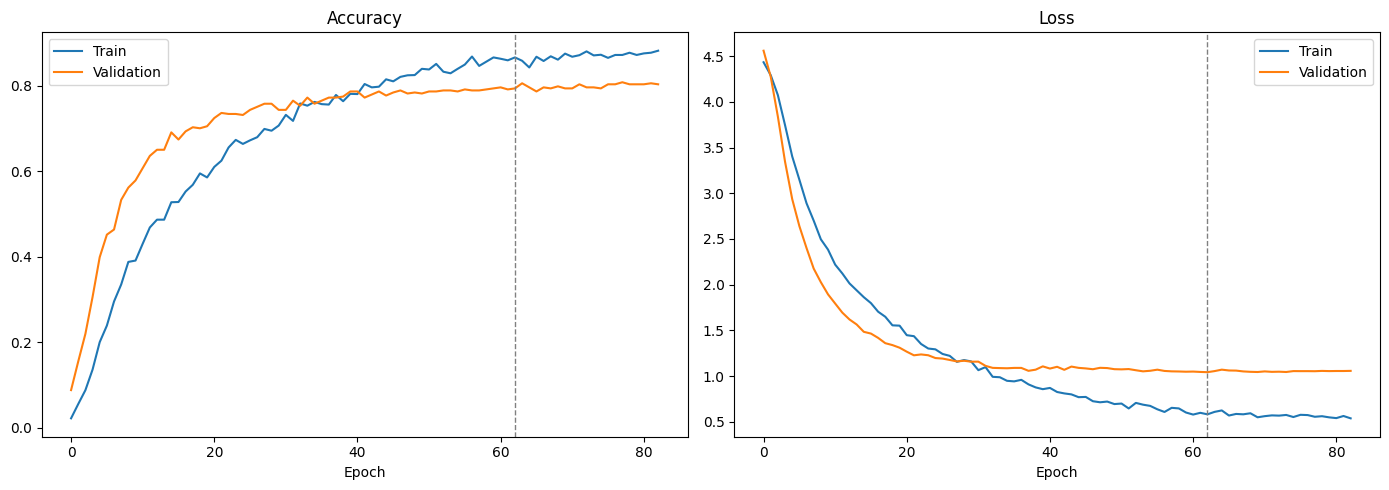

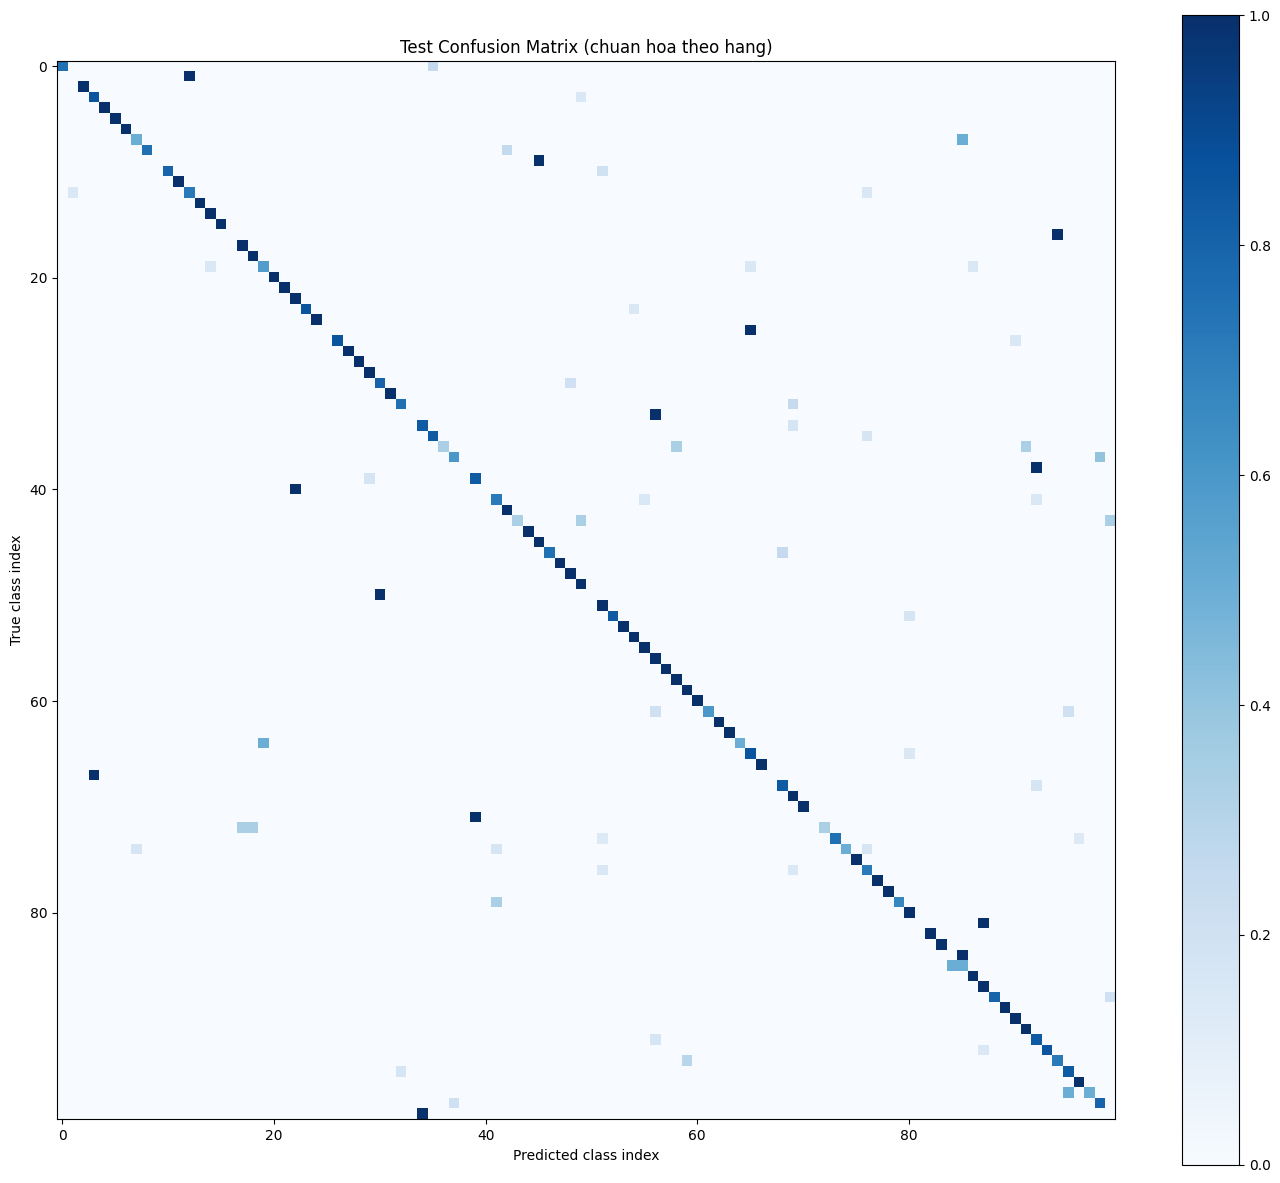

Cac cap nham nhieu nhat (that -> doan: so mau):
  Ban ngày -> Chiều: 2
  Chúng ta -> Đi: 2
  Họ -> Đồng ý: 2
  Đi -> Phía sau: 2
  An ủi -> Hâm mộ: 1
  Biết -> Nghỉ ngơi: 1
  Bạn thân -> Xe đạp: 1
  Bế mạc -> Khẩu trang: 1
  Bệnh nhân -> Lây bệnh: 1
  Bệnh viện -> Nhà: 1
  Chiều -> Ban ngày: 1
  Chiều -> Trường học: 1
  Chậm lại -> Chào: 1
  Chậm lại -> Rẽ trái: 1
  Chậm lại -> Xin lỗi: 1

15 lop co F1 thap nhat:
             precision  recall  f1-score  support  train_support
Ban ngày          0.00     0.0       0.0      2.0             11
Bệnh nhân         0.00     0.0       0.0      1.0              3
Cơ thể            0.00     0.0       0.0      1.0              3
Chúng ta          0.00     0.0       0.0      2.0              7
Ngón tay          0.00     0.0       0.0      1.0              3
Khu cách ly       0.00     0.0       0.0      1.0              7
Học sinh          0.00     0.0       0.0      1.0              3
Ho                0.00     0.0       0.0      1.0              

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# 1) Duong cong huan luyen
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(history_df['accuracy'], label='Train'); ax[0].plot(history_df['val_accuracy'], label='Validation')
ax[0].axvline(best_idx, color='gray', ls='--', lw=1); ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(history_df['loss'], label='Train'); ax[1].plot(history_df['val_loss'], label='Validation')
ax[1].axvline(best_idx, color='gray', ls='--', lw=1); ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig(RESULT_DIR / 'training_curves.png', dpi=200); plt.show()

# 2) Ma tran nham lan (chuan hoa theo hang)
cm = confusion_matrix(y_test, pred, labels=np.arange(len(le.classes_)))
np.save(RESULT_DIR / 'confusion_matrix.npy', cm)
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
plt.figure(figsize=(14, 12)); plt.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
plt.title('Test Confusion Matrix (chuan hoa theo hang)'); plt.xlabel('Predicted class index'); plt.ylabel('True class index')
plt.colorbar(); plt.tight_layout(); plt.savefig(RESULT_DIR / 'confusion_matrix.png', dpi=200); plt.show()

# 3) Cap nham nhieu nhat (co ten lop)
pairs = sorted(((le.classes_[i], le.classes_[j], int(cm[i, j])) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0),
               key=lambda t: -t[2])[:15]
print('Cac cap nham nhieu nhat (that -> doan: so mau):')
for a, b, k in pairs:
    print(f'  {a} -> {b}: {k}')

# 4) Lop kem nhat va moi lien he voi so mau train
per = rep.iloc[:len(le.classes_)].copy()
per['train_support'] = [int(counts[i]) for i in range(len(le.classes_))]
print('\n15 lop co F1 thap nhat:')
print(per.sort_values('f1-score').head(15)[['precision', 'recall', 'f1-score', 'support', 'train_support']].round(2).to_string())
rho, pval = spearmanr(per['train_support'], per['f1-score'])
print(f'\nTuong quan Spearman giua so mau train va F1 cua lop: rho={rho:.2f} (p={pval:.3f})')
per.to_csv(RESULT_DIR / 'per_class_with_support.csv', encoding='utf-8-sig')

## Cell 12A - Xuất sản phẩm (model, scaler, encoder, config, module đặc trưng)

In [ ]:
import sklearn, mediapipe as mp

PRODUCT.mkdir(parents=True, exist_ok=True)
files = {
    'best_model.keras': MODEL_DIR / 'best_model.keras',
    'scaler.pkl': ART / 'scaler.pkl',
    'label_encoder.pkl': ART / 'label_encoder.pkl',
    'config.json': ART / 'config.json',
    'visign_features.py': Path('/content/visign_features.py'),
}
for name, src in files.items():
    shutil.copy2(src, PRODUCT / name)

cfg = json.loads((PRODUCT / 'config.json').read_text(encoding='utf-8'))
cfg['test_metrics'] = metrics
cfg['model'] = {'name': model.name, 'params': int(model.count_params()), 'epochs_run': len(history_df)}
(PRODUCT / 'config.json').write_text(json.dumps(cfg, ensure_ascii=False, indent=2), encoding='utf-8')

versions = {'tensorflow': tf.__version__, 'keras': keras.__version__, 'mediapipe': mp.__version__,
            'scikit_learn': sklearn.__version__, 'numpy': np.__version__}
(PRODUCT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

required = ['best_model.keras', 'scaler.pkl', 'label_encoder.pkl', 'config.json', 'visign_features.py', 'versions.json']
for f in required:
    print('OK' if (PRODUCT / f).exists() else 'MISSING', f)
assert all((PRODUCT / f).exists() for f in required)
print('PRODUCT SAVED:', PRODUCT)

OK best_model.keras
OK scaler.pkl
OK label_encoder.pkl
OK config.json
OK visign_features.py
OK versions.json
PRODUCT SAVED: /content/drive/MyDrive/ViSignLanguage_Project/ViSignLanguage_Product_V5_Face


## Cell 12B - Dự đoán một video mới từ thư mục sản phẩm



In [ ]:
import importlib.util
spec = importlib.util.spec_from_file_location('visign_features_product', PRODUCT / 'visign_features.py')
VP = importlib.util.module_from_spec(spec); spec.loader.exec_module(VP)

p_model = tf.keras.models.load_model(str(PRODUCT / 'best_model.keras'), custom_objects={'TemporalAttention': TemporalAttention}, compile=False)
p_scaler = joblib.load(PRODUCT / 'scaler.pkl')
p_le = joblib.load(PRODUCT / 'label_encoder.pkl')

def predict_video(path, topk=5):
    hand_d, pose_d, face_d = VP.make_detectors(USE_TRACKING)
    with hand_d as hand, pose_d as pose, face_d as face:
        raw = VP.process_video(path, hand, pose, face, VP.T, USE_TRACKING)
    probs = p_model.predict(VP.apply_scaler(raw[None, ...], p_scaler), verbose=0)[0]
    top = np.argsort(probs)[::-1][:topk]
    return [(p_le.classes_[i], float(probs[i])) for i in top], raw

TEST_VIDEO = test_f.iloc[0]['path']           # thay bang duong dan video bat ky (chua mot ky hieu)
result, raw = predict_video(TEST_VIDEO)
print('Video:', TEST_VIDEO, '| nhan that:', test_f.iloc[0]['label'])
for name, p in result:
    print(f'  {name}: {p:.4f}')

cached = np.load(test_f.iloc[0]['feature'])
print('Khop voi dac trung cache luc huan luyen, sai lech toi da:', float(np.abs(raw - cached).max()))

Video: /content/visign_data/dataset/train/An ủi/127824.mp4 | nhan that: An ủi
  An ủi: 0.6443
  Ủng hộ: 0.2529
  Giúp: 0.0924
  Phạt: 0.0031
  San sẻ: 0.0024
Khop voi dac trung cache luc huan luyen, sai lech toi da: 0.0


## Cell 13 — Video nhiều gloss: cắt theo chuyển động rồi dự đoán từng đoạn



In [ ]:
import cv2, tempfile, os
from pathlib import Path

def split_continuous_video(video_path, motion_threshold=0.012, idle_seconds=0.65,
                           min_seconds=0.35, max_seconds=4.5):
    """Baseline: motion dựa trên khác biệt ảnh xám; trả về các đoạn (frame_start, frame_end)."""
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps < 1: fps = 25.0
    energies, previous, count = [], None, 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        gray = cv2.resize(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (96, 72))
        gray = cv2.GaussianBlur(gray, (5, 5), 0)
        energy = 0.0 if previous is None else float(np.mean(cv2.absdiff(gray, previous))/255.)
        energies.append(energy); previous = gray; count += 1
    cap.release()
    if count == 0: raise ValueError('Video không đọc được')
    active = np.asarray(energies) >= motion_threshold
    gap = max(1, round(idle_seconds * fps))
    min_len, max_len = round(min_seconds*fps), round(max_seconds*fps)
    # Mở rộng các vùng chuyển động và gộp các khoảng nghỉ ngắn.
    inds = np.flatnonzero(active)
    if len(inds) == 0: return [], fps
    groups = []; start = last = int(inds[0])
    for ix in inds[1:]:
        ix = int(ix)
        if ix - last > gap:
            groups.append((start,last));start=ix
        last=ix
    groups.append((start,last))
    segments=[]
    for a,b in groups:
        a=max(0,a-round(.2*fps)); b=min(count-1,b+round(.25*fps))
        if b-a+1 < min_len:continue
        for s in range(a,b+1,max(1,max_len)):
            e=min(b+1,s+max(1,max_len))
            if e-s>=min_len:segments.append((s,e))
    return segments,fps

def predict_continuous_video(video_path, min_confidence=0.0):
    segments,fps=split_continuous_video(video_path)
    if not segments:
        print('Không tìm thấy đoạn chuyển động đủ dài. Thử giảm motion_threshold.')
        return []
    cap=cv2.VideoCapture(str(video_path)); out=[]
    with tempfile.TemporaryDirectory() as tmp:
        for j,(start,end) in enumerate(segments):
            cap.set(cv2.CAP_PROP_POS_FRAMES,start)
            tmp_path=str(Path(tmp)/f'segment_{j:03d}.mp4')
            writer=None; n=0
            for _ in range(end-start):
                ok,fr=cap.read()
                if not ok:break
                if writer is None:
                    h,w=fr.shape[:2]
                    writer=cv2.VideoWriter(tmp_path,cv2.VideoWriter_fourcc(*'mp4v'),fps,(w,h))
                    if not writer.isOpened():raise RuntimeError('Không ghi được video tạm')
                writer.write(fr);n+=1
            if writer is not None:writer.release()
            if n<3:continue
            preds,_=predict_video(tmp_path,topk=5)
            if preds[0][1]>=min_confidence:
                out.append({'start_sec':round(start/fps,2),'end_sec':round(end/fps,2),
                            'gloss':str(preds[0][0]),'confidence':float(preds[0][1]),'top5':preds})
    cap.release()
    return out

# Đổi thành đường dẫn video dài thật (gồm nhiều ký hiệu) rồi chạy:
CONTINUOUS_VIDEO = '/content/drive/MyDrive/ViSignLanguage_Project/120422.mp4'
if CONTINUOUS_VIDEO:
    segments_pred = predict_continuous_video(CONTINUOUS_VIDEO, min_confidence=0.4)
    gloss_sequence = [x['gloss'] for x in segments_pred]
    print('Gloss:', ' / '.join(gloss_sequence))
else:
    print('Đã khai báo hàm. Hãy đặt CONTINUOUS_VIDEO thành đường dẫn video dài để chạy.')

Gloss: Băn khoăn


## Cell 14 — Gloss → câu tiếng Việt tự nhiên bằng LLM



In [ ]:
from google.colab import userdata

key = userdata.get("GROQ_API_KEY")

if key:
    print("API KEY DA SAN SANG")
else:
    print("CHUA CO API KEY")

API KEY DA SAN SANG


In [ ]:

# CELL 14 - GLOSS TO TEXT (GROQ API)

%pip -q install groq

import os
from groq import Groq
from google.colab import userdata

GROQ_MODEL = "openai/gpt-oss-20b"

def gloss_to_sentence(glosses, use_llm=False, client=None):
    glosses = [str(g).strip() for g in glosses if str(g).strip()]

    if not glosses:
        return ""

    baseline = " ".join(glosses) + "."

    if not use_llm:
        return baseline

    if client is None:
        key = os.environ.get("GROQ_API_KEY")
        if not key:
            key = userdata.get("GROQ_API_KEY")
        client = Groq(api_key=key)

    response = client.chat.completions.create(
        model=GROQ_MODEL,
        messages=[
            {
                "role": "system",
                "content": (
                    "Bạn là hệ thống dịch gloss ngôn ngữ ký hiệu Việt Nam. "
                    "Chuyển chuỗi gloss thành câu tiếng Việt tự nhiên. "
                    "Giữ nguyên ý nghĩa, không thêm thông tin. "
                    "Chỉ trả về câu dịch, không giải thích."
                )
            },
            {
                "role": "user",
                "content": " / ".join(glosses)
            }
        ],
        temperature=0,
        max_completion_tokens=300
    )

    sentence = response.choices[0].message.content
    return sentence.strip() if sentence else baseline

print("Groq Gloss-to-Text da san sang!")


Groq Gloss-to-Text da san sang!


In [ ]:
glosses = ["Tôi", "Muốn", "Học", "Tốt", "AI"]

print("Gloss:", " / ".join(glosses))
print("Câu dịch:", gloss_to_sentence(glosses, use_llm=True))

Gloss: Tôi / Muốn / Học / Tốt / AI
Câu dịch: Tôi muốn học tốt AI.


In [ ]:

# CELL 14.1 - TICH HOP V5 + GROQ LLM

# Lay chuoi gloss do V5 du doan
gloss_sequence = [
    x["gloss"] for x in segments_pred
]

print("=== KET QUA NHAN DIEN V5 ===")
print("Gloss:", " / ".join(gloss_sequence))

# Goi Groq de dich thanh cau
if gloss_sequence:
    sentence = gloss_to_sentence(
        gloss_sequence,
        use_llm=True
    )

    print("\n=== KET QUA DICH LLM ===")
    print("Cau tieng Viet:", sentence)
else:
    print("Chua nhan dien duoc gloss.")


=== KET QUA NHAN DIEN V5 ===
Gloss: Băn khoăn

=== KET QUA DICH LLM ===
Cau tieng Viet: Băn khoăn.


In [ ]:

import cv2

cap = cv2.VideoCapture(CONTINUOUS_VIDEO)

fps = cap.get(cv2.CAP_PROP_FPS)
frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)

duration = frames / fps if fps > 0 else 0

cap.release()

print("Video:", CONTINUOUS_VIDEO)
print("FPS:", round(fps, 2))
print("Tong frame:", int(frames))
print("Thoi luong:", round(duration, 2), "giay")

print("\nSo segment:", len(segments_pred))

for i, segment in enumerate(segments_pred, 1):
    print(f"Segment {i}:", segment)


Video: /content/drive/MyDrive/ViSignLanguage_Project/120422.mp4
FPS: 12.87
Tong frame: 30
Thoi luong: 2.33 giay

So segment: 1
Segment 1: {'start_sec': 0.0, 'end_sec': 2.33, 'gloss': 'Băn khoăn', 'confidence': 0.9995133876800537, 'top5': [('Băn khoăn', 0.9995133876800537), ('Biết', 0.00028550895513035357), ('Nghỉ ngơi', 9.203847002936527e-05), ('Đầu', 3.889108484145254e-05), ('Chạy', 2.1690497305826284e-05)]}


In [ ]:
import os

CONTINUOUS_VIDEO = "/content/drive/MyDrive/ViSignLanguage_Project/video demo.mp4"

print("Video tồn tại:", os.path.exists(CONTINUOUS_VIDEO))

Video tồn tại: True


In [ ]:
segments_pred = predict_continuous_video(
    CONTINUOUS_VIDEO,
    min_confidence=0.4
)

gloss_sequence = [x["gloss"] for x in segments_pred]

print("Số gloss nhận diện:", len(gloss_sequence))
print("Chuỗi gloss:", " / ".join(gloss_sequence))

for i, segment in enumerate(segments_pred, 1):
    print(f"Segment {i}:", segment)

if gloss_sequence:
    sentence = gloss_to_sentence(
        gloss_sequence,
        use_llm=True
    )
    print("Câu dịch Groq:", sentence)

Số gloss nhận diện: 1
Chuỗi gloss: Tập luyện
Segment 1: {'start_sec': 0.0, 'end_sec': 2.31, 'gloss': 'Tập luyện', 'confidence': 0.9911661744117737, 'top5': [('Tập luyện', 0.9911661744117737), ('Chiều', 0.004321558866649866), ('Cần', 0.0017630353104323149), ('Cám dỗ', 0.0014235436683520675), ('Chậm lại', 0.0003923825570382178)]}
Câu dịch Groq: Tập luyện.
